# Project 1 — Estimating corporate credit spreads
FIN 453 / FIN 553 — Fall 2026

**Due Friday, October 9, 2026, at 11:59 p.m. Central Time, through Canvas.**
This individual project is worth **20% of the course grade**.

You are building a prediction tool for a credit analyst. Estimate a corporate
bond's **credit spread**, its yield difference relative to a comparable
benchmark bond, from company financial characteristics. Spreads are measured
in **basis points (bps): 100 bps = 1 percentage point of annual yield**.
All bonds share currency, maturity, and seniority. This is a stylized
prediction exercise, not a calibrated pricing model or a causal analysis.

You are provided with two files:

- `development.csv`: 12,000 labeled observations for training and validation.
- `test_features.csv`: 5,000 unlabeled observations for final predictions.
  The instructor alone retains the test labels.

Each row represents a different, independently sampled company. The development
file is sorted by leverage, **not by time**. Your model should predict spreads
for another independent company from this population.

| Part | Task | Points |
|---|---|---:|
| 1 | Split the data and prepare features | 20 |
| 2 | Fit a linear JAX baseline | 30 |
| 3 | Compare three models with cross-validation | 35 |
| 4 | Refit and submit hidden-test predictions | 15 |

**Deliverables:** your completed, executed notebook and `predictions.csv`.
Include two figures (split coverage and training loss), one cross-validation
comparison table, and six short explanations. Two to four sentences per
explanation are enough. No separate report or extra plots are required.
Use fixed seeds and restart/run all cells before submitting.

## Working rules
Use `jax.numpy` for your differentiable loss, **`jax.grad` for all optimization
gradients**, and `jax.jit` for your update. Fit models with your own training
loop; do not replace it with a direct least-squares solve or a prebuilt model
fitting routine. NumPy, pandas, Matplotlib, and Optax are allowed. You may use
Optax to implement the Adam algorithm discussed in class; use one optimizer
consistently. You do **not** need
to compare optimizers or measure execution time.

Work entirely individually. Do not discuss any aspect of the project with
anyone except the instructor, or share/view/compare project code or results.
AI assistance with a specific coding question, debugging, or understanding a
function is allowed. Do not give an AI tool the entire problem or significant
portions and ask for a complete solution. You must understand your submission.

## Setup and data dictionary
Place both CSV files in the notebook's working directory. In Colab, upload
them using the Files panel; upload again if the runtime resets. The supplied
cells load the files.

Packages: `numpy`, `pandas`, `matplotlib`, `jax`, and `optax`. If a package is
missing, install it in a separate setup cell and restart the kernel if needed.

| Column | Meaning |
|---|---|
| `row_id` | Identifier only; never a model feature |
| `leverage` | Debt/assets |
| `interest_coverage` | Earnings/interest expense |
| `liquidity` | Current assets/current liabilities |
| `profitability` | Operating earnings/assets |
| `asset_volatility` | Annualized asset-return volatility |
| `log_size` | Log asset-size index, in fixed arbitrary units |
| `signal_a`, `signal_b` | Additional candidate analyst signals |
| `spread_bps` | Observed spread; development data only |

Train on **t = spread_bps / 100** and multiply predictions by 100 for reporting
and export. This is a fixed unit conversion. Evaluate predictions with MSE;
RMSE = sqrt(MSE) expresses an error in bps. The training loss includes the
classroom factor 1/2; evaluation MSE does not. Do not include the ridge penalty
in validation/test prediction errors.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import jax
import jax.numpy as jnp
import optax

In [2]:
DATA_DIR = Path(".")  # Change only if the supplied CSV files are elsewhere.

FEATURES = ["leverage", "interest_coverage", "liquidity", "profitability",
            "asset_volatility", "log_size", "signal_a", "signal_b"]
TARGET, UNIT = "spread_bps", 100.0
SPLIT_SEED, CV_SEED = 2026, 404
LEARNING_RATE, TRAINING_STEPS, BATCH_SIZE = 0.01, 2000, 256
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
print({"numpy": np.__version__, "pandas": pd.__version__,
       "jax": jax.__version__, "optax": optax.__version__})


def mse_bps(y_bps, predictions_bps):
    return float(np.mean((np.asarray(y_bps)-np.asarray(predictions_bps))**2))


def rmse_bps(y_bps, predictions_bps):
    return np.sqrt(mse_bps(y_bps, predictions_bps))

{'numpy': '2.0.1', 'pandas': '2.2.2', 'jax': '0.10.2', 'optax': '0.2.8'}


In [3]:
development_path = DATA_DIR / "development.csv"
if not development_path.exists():
    raise FileNotFoundError("Upload development.csv to DATA_DIR before running this cell.")
development = pd.read_csv(development_path, dtype={"row_id": str})


assert list(development.columns) == ["row_id", *FEATURES, TARGET]
assert development.row_id.is_unique and not development.isna().any().any()
assert np.isfinite(development[FEATURES + [TARGET]].to_numpy()).all()
print("Development observations:", len(development))
display(development.head())

Development observations: 12000


,row_id,leverage,interest_coverage,liquidity,profitability,asset_volatility,log_size,signal_a,signal_b,spread_bps
0,row_b6dd659cb9b0adb38acb,0.100057,7.543133,2.942396,-0.078123,0.393711,8.316000,-1.423670,0.185515,242.359813
1,row_287e87fc1dea660d5a60,0.100165,1.427591,1.334815,0.181396,0.400039,9.064546,1.547084,-0.488185,252.023952
2,row_7951797341fbabe83155,0.100328,6.718288,0.575651,0.137754,0.347869,6.675562,0.226110,-1.258285,245.159185
3,row_7613f174b85d3c19f328,0.100335,2.735904,2.308494,-0.071012,0.621651,6.974965,1.833744,-1.239995,256.647460
4,row_e1ce26a37171620865dd,0.100381,2.373887,1.108179,0.161518,0.567401,5.818393,-0.332160,0.366268,255.591973


 ## Part 1 — Splitting and preprocessing (20 points)
Create two 80%/20% train/validation splits: first by slicing the sorted file,
then using **one** seeded NumPy permutation of row indices. Use the same
indices for features and labels. Check the random split's sizes, disjointness,
and complete coverage. Keep that split for Part 2.

**Supplement:** a permutation rearranges observation indices. Applying it to
both features and labels preserves their correspondence. An ordered split here
holds out high-leverage companies; a random split represents another independent
draw from the full population. Randomization need not improve every realized
score. For forecasting, future dates would generally belong after training.

Make **one figure** comparing leverage coverage in ordered and random splits
(two panels are fine). In Part 2, compare the same baseline model on both
splits. No additional models are needed for this figure.

Implement reusable preprocessing: begin with the eight feature columns, learn
each column's mean and standard deviation on TRAINING rows only, reuse those
values on other rows, and add an intercept column of ones. Treat a zero standard
deviation as 1. Never include `row_id` or the target as features.

**Explanation 1:** Why does ordered splitting test extrapolation here? Would
random splitting be appropriate for predicting next year's spreads from earlier years?

In [4]:
seed = 54 # global seed used

In [5]:
def split_indices(n, seed=SPLIT_SEED):
    """Return random train/validation index arrays (80% / 20%)."""
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    n_train = int(0.8*n)
    train_idx = perm[:n_train]
    val_idx = perm[n_train:]

    # check for size
    assert len(train_idx) == n_train, f"Expected {n_train} train rows, got {len(train_idx)}"
    assert len(val_idx) == n - n_train, f"Expected {n - n_train} val rows, got {len(val_idx)}"
    
    # check for overlap

    assert len(np.intersect1d(train_idx, val_idx)) == 0, "Overlap Detected"
    
    # check for coverage
    all_indices = np.sort(np.concatenate([train_idx, val_idx]))
    assert np.array_equal(all_indices, np.arange(n)), "Coverage Incomplete"
    return train_idx, val_idx

In [6]:
def feature_matrix(frame, expanded=False):
    """Raw feature columns WITHOUT an intercept; extend in Part 3."""
    X_raw = frame[FEATURES].to_numpy(dtype=np.float32)
    if expanded:
        lev_idx = FEATURES.index("leverage")
        int_cov_idx = FEATURES.index("interest_coverage")
        vol_idx = FEATURES.index("asset_volatility")
        
        lev_sq = X_raw[:, lev_idx] ** 2
        int_cov_sq = X_raw[:, int_cov_idx] ** 2
        lev_x_vol = X_raw[:, lev_idx] * X_raw[:, vol_idx]
        X_raw = np.column_stack([X_raw, lev_sq, int_cov_sq, lev_x_vol])
    return X_raw

In [7]:
def fit_preprocessor(frame, expanded=False):
    """Return a dict with expanded, mean, scale fitted to these training rows."""
    X_raw = feature_matrix(frame, expanded=expanded)
    mean = np.mean(X_raw, axis=0)
    scale = np.std(X_raw, axis=0)
    scale = np.where(scale == 0.0, 1.0, scale)

    return {
        "expanded": expanded,
        "mean": mean.astype(np.float32),
        "scale": scale.astype(np.float32),
    }   

In [8]:
def transform(frame, preprocessor):
    """Apply saved preprocessing; return float32 features with an intercept."""
    X_raw = feature_matrix(frame, expanded=preprocessor["expanded"])
    X_scaled = (X_raw - preprocessor["mean"]) / preprocessor["scale"]
    intercept = np.ones((len(frame), 1), dtype=np.float32)
    return np.column_stack([intercept, X_scaled]).astype(np.float32)


In [9]:
n_total = len(development)
n_train = int(0.8 * n_total)

ord_train_idx = np.arange(n_train)
ord_val_idx = np.arange(n_train, n_total)

rand_train_idx, rand_val_idx = split_indices(n_total, seed=SPLIT_SEED)


t_all = (development[TARGET].to_numpy(dtype=np.float32) / UNIT)


train_ord = development.iloc[ord_train_idx]
val_ord = development.iloc[ord_val_idx]
preproc_ord = fit_preprocessor(train_ord, expanded=False)
X_train_ord = transform(train_ord, preproc_ord)
X_val_ord = transform(val_ord, preproc_ord)
t_train_ord = t_all[ord_train_idx]
t_val_ord = t_all[ord_val_idx]

train_rand = development.iloc[rand_train_idx]
val_rand = development.iloc[rand_val_idx]
preproc_rand = fit_preprocessor(train_rand, expanded=False)
X_train_rand = transform(train_rand, preproc_rand)
X_val_rand = transform(val_rand, preproc_rand)
t_train_rand = t_all[rand_train_idx]
t_val_rand = t_all[rand_val_idx]

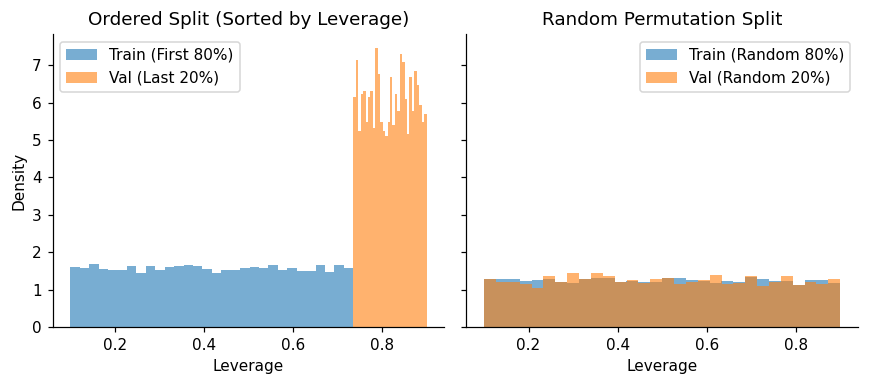

In [10]:
fig, axes = plt.subplots(1, 2, sharey=True)

# Panel A: Ordered Split
axes[0].hist(train_ord["leverage"], bins=30, alpha=0.6, density=True, label="Train (First 80%)")
axes[0].hist(val_ord["leverage"], bins=30, alpha=0.6, density=True, label="Val (Last 20%)")
axes[0].set_title("Ordered Split (Sorted by Leverage)")
axes[0].set_xlabel("Leverage")
axes[0].set_ylabel("Density")
axes[0].legend()

# Panel B: Random Split
axes[1].hist(train_rand["leverage"], bins=30, alpha=0.6, density=True, label="Train (Random 80%)")
axes[1].hist(val_rand["leverage"], bins=30, alpha=0.6, density=True, label="Val (Random 20%)")
axes[1].set_title("Random Permutation Split")
axes[1].set_xlabel("Leverage")
axes[1].legend()

plt.tight_layout()
plt.show()

**Explanation 1:** 

Since the original 'development.csv' training data was sorted by leverage, an ordered split made by just slicing values will put the 80% least levered companies in the training and the 20% most levered in the validation set. This results in testing out of distribution extrapolation, where the model's validation score is being determined by its ability to generalize to predicting the spreads of firms levered to values higher than its seen. 

When it comes to predicting future spreads from earlier years, random splitting would not be appropriate. This is because randomly partitioning time series data leaks future macroeconomic regimes. Forecasting requires a chronological split, where training data period precedes the test period.

## Part 2 — Linear regression with JAX (30 points)
With design matrix A, coefficients theta, and t = spread_bps/100, implement

$$L(\theta)=\frac{1}{2m}\sum_{i=1}^m(A_i\theta-t_i)^2.$$

Obtain the gradient with **`jax.grad`** and compile the update with `jax.jit`.
By default, `jax.grad(loss)` differentiates the first argument: theta in the
supplied function signature. Calling the resulting function returns a
gradient, not updated parameters.
No analytical-gradient derivation or implementation is requested. Write one
reusable training function, resetting parameters AND optimizer state on every
call. Reuse it throughout the project.

Suggested settings: Adam, learning rate 0.01, 2,000 updates, batch size 256, and
a fixed sampling seed. Mini-batch row indices must select A and t together.
Optax handles Adam's internal updates; you implement the loss and training loop.
Use one optimizer, not a comparison study. You may adjust settings if needed
for sensible training, then use the same settings for all candidates in Part 3.
These suggested settings assume Adam; another optimizer may need a different
learning rate or number of updates.

**Optax API reference** (not a complete training loop):

```python
optimizer = optax.adam(LEARNING_RATE)
state = optimizer.init(theta)                         # once per fresh fit
updates, state = optimizer.update(grads, state, theta) # on each update
theta = optax.apply_updates(theta, updates)
```
Here `grads` is the gradient you compute on the current mini-batch. Keep the
returned state for the next update; do not reinitialize it inside the loop.
You still implement the loss, mini-batch selection, jitted update, and loop.
API details: [JAX grad](https://docs.jax.dev/en/latest/_autosummary/jax.grad.html)
and [Optax](https://optax.readthedocs.io/en/latest/getting_started.html).

Check that the loss is scalar, the gradient has theta's shape and finite values,
and training reduces the loss. Make **one training-loss plot** for the random
baseline. Report its training and validation RMSE in bps. Also report validation
RMSE for the same linear model fitted to the ordered training split (with its
OWN scaler), and for a constant prediction equal to the random training mean.
A few printed numbers are enough.

**Explanation 2:** What do `jax.grad` and `jax.jit` each do in your code? State
the shapes of A, theta, predictions, and the scalar loss.

**Explanation 3:** Compare your results. Why learn feature means/scales on
training rows only? Why does falling training loss alone not establish good
predictions on new companies?

Loss is scalar: True (Value: 7.5676)
Gradient shape matches theta: True (Shape: (9,))
Gradient is finite: True

Training reduces loss (Random Split): True (Start: 7.7285 -> End: 0.0342)

--- RMSE Results (bps) ---
Random Split Train RMSE:       27.33
Random Split Val RMSE:         28.07
Ordered Split Val RMSE:        61.11
Constant Benchmark Val RMSE:   83.68


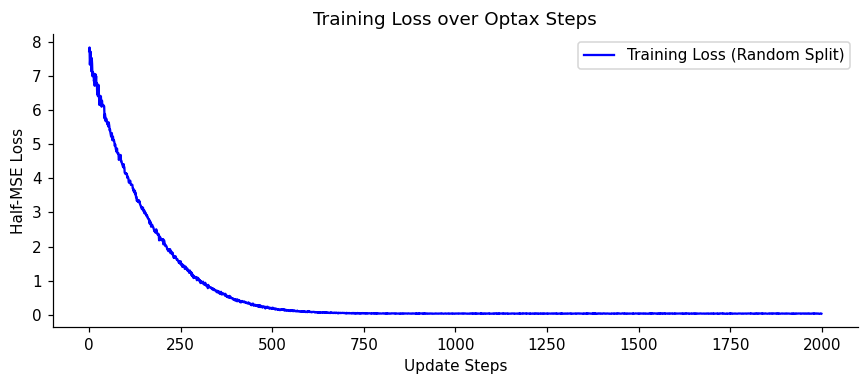

In [11]:
def loss(theta, A, t, lam=0.0):
    """Scalar half-MSE; add the slopes-only ridge penalty in Part 3."""
    predictions = A @ theta
    mse = jnp.mean((predictions - t) ** 2) / 2.0
    ridge_penalty = (lam / 2.0) * jnp.sum(theta[1:] ** 2)
    return mse + ridge_penalty


def train(A, y_bps, lam=0.0, seed=40):
    """Return fitted theta and loss history; scale y internally."""
    A_jnp = jnp.asarray(A)
    t_jnp = jnp.asarray(y_bps) / UNIT
    theta = jnp.zeros(A_jnp.shape[1], dtype=jnp.float32)
    optimizer = optax.adam(LEARNING_RATE)
    state = optimizer.init(theta)
    loss_grad_fn = jax.grad(loss)   

    @jax.jit
    def step(theta_curr, state_curr, A_batch, t_batch):
        grads = loss_grad_fn(theta_curr, A_batch, t_batch, lam)
        updates, state_next = optimizer.update(grads, state_curr, theta_curr)
        theta_next = optax.apply_updates(theta_curr, updates)
        loss_val = loss(theta_curr, A_batch, t_batch, lam)
        return theta_next, state_next, grads, loss_val

    rng = np.random.default_rng(seed)
    m = len(A_jnp)
    history = []
        
    for _ in range(TRAINING_STEPS):

        batch_idx = rng.choice(m, BATCH_SIZE, replace=False)
        A_batch = A_jnp[batch_idx]
        t_batch = t_jnp[batch_idx]
        theta, state, grads, loss_val = step(theta, state, A_batch, t_batch)
        history.append(float(loss_val))
    return theta, history




y_train_rand_bps = development.iloc[rand_train_idx][TARGET].to_numpy()
y_val_rand_bps = development.iloc[rand_val_idx][TARGET].to_numpy()
y_train_ord_bps = development.iloc[ord_train_idx][TARGET].to_numpy()
y_val_ord_bps = development.iloc[ord_val_idx][TARGET].to_numpy()


dummy_theta = jnp.zeros(X_train_rand.shape[1])
dummy_loss = loss(dummy_theta, X_train_rand[:BATCH_SIZE], (y_train_rand_bps[:BATCH_SIZE]/UNIT))
dummy_grad = jax.grad(loss)(dummy_theta, X_train_rand[:BATCH_SIZE], (y_train_rand_bps[:BATCH_SIZE]/UNIT))


print(f"Loss is scalar: {dummy_loss.ndim == 0} (Value: {dummy_loss:.4f})")
print(f"Gradient shape matches theta: {dummy_grad.shape == dummy_theta.shape} (Shape: {dummy_grad.shape})")
print(f"Gradient is finite: {jnp.isfinite(dummy_grad).all()}\n")


theta_rand, hist_rand = train(X_train_rand, y_train_rand_bps)


theta_ord, hist_ord = train(X_train_ord, y_train_ord_bps)

loss_reduced = hist_rand[-1] < hist_rand[0]
print(f"Training reduces loss (Random Split): {loss_reduced} (Start: {hist_rand[0]:.4f} -> End: {hist_rand[-1]:.4f})\n")


pred_train_rand_bps = np.asarray(X_train_rand @ theta_rand) * UNIT
pred_val_rand_bps = np.asarray(X_val_rand @ theta_rand) * UNIT
pred_val_ord_bps = np.asarray(X_val_ord @ theta_ord) * UNIT

constant_pred = np.mean(y_train_rand_bps)
pred_const_val_bps = np.full(len(y_val_rand_bps), constant_pred)

print("--- RMSE Results (bps) ---")
print(f"Random Split Train RMSE:       {rmse_bps(y_train_rand_bps, pred_train_rand_bps):.2f}")
print(f"Random Split Val RMSE:         {rmse_bps(y_val_rand_bps, pred_val_rand_bps):.2f}")
print(f"Ordered Split Val RMSE:        {rmse_bps(y_val_ord_bps, pred_val_ord_bps):.2f}")
print(f"Constant Benchmark Val RMSE:   {rmse_bps(y_val_rand_bps, pred_const_val_bps):.2f}")


plt.plot(hist_rand, label='Training Loss (Random Split)', color='blue')
plt.title('Training Loss over Optax Steps')
plt.xlabel('Update Steps')
plt.ylabel('Half-MSE Loss')
plt.legend()
plt.tight_layout()
plt.show()

**Explanation 2:**

jax.grad analytically computes the gradient of the loss function with respect to the first parameter theta, while jax.jit compiles the step function with just in time compilation, significantly speeding up the process. 

The design matrix is shaped (9600, 9) representing the portioned samples used along with 8 features + 1 intercept. Theta has a shape of (9,) representing the coefficients / weights. Predictions have a shape of (256,) matching the length of the batch size and design matrix. Scalar loss is () for a single 0-dimensional float.

**Explanation 3:** 

Learning scaling parameter on just training data prevents data leakage. Knowing the summary numbers of future test/validation points distorts the model, meaning information about the out of training distribution unfairly influences the training process. This results in biased predictions and an overestimation of the true capability of the model to generalize. 

Falling training loss alone typically leads to but does not ensure improved performance on unseen data, as the model may overfit and memorize statistical noise that is not indicative of real trends in the data. 

## Part 3 — Three models and three-fold cross-validation (35 points)
Compare **exactly three** candidates. Extend the feature builder with only
these three columns, computed from the original, unstandardized features:

$$\text{leverage}^2,\qquad \text{interest\_coverage}^2,\qquad
  \text{leverage}\times\text{asset\_volatility}.$$

Construct raw columns first; learn means/scales for ALL columns on the training
rows of that fit. Add the intercept after standardization.

| Candidate | Features before intercept | Ridge lambda |
|---|---|---:|
| Linear | Original 8 columns | 0 |
| Expanded | Original 8 plus the 3 specified terms | 0 |
| Expanded + ridge | Same 11 columns | 0.01 |

Use the supplied ridge value, without a penalty search. Extend the loss to

$$L_\lambda(\theta)=\frac{1}{2m}\sum_i(A_i\theta-t_i)^2
                    +\frac{\lambda}{2}\sum_{j=1}^{p-1}\theta_j^2.$$

theta[0] is the intercept and is **not** penalized. Lecture 4 penalized every
coefficient and divided the penalty by N. Here the penalty is **not divided
by m**, so the numerical values of lambda are not directly comparable between
those conventions. Follow the formula above. The data term is a mean, not
a sum; lambda is not the optimizer's learning rate.

**Cross-validation tutorial:** shuffle all development indices once using
`CV_SEED` and divide them into three equal folds. Fit on two folds, score the
third, and repeat so each fold is held out once. Reuse the SAME folds for all
candidates. This requires **nine fresh fits**, not one fit scored nine times.
The original Part 1 split is replaced by these folds; the separate test stays
untouched. Each fit needs training-fold preprocessing and fresh theta AND
optimizer state.

Make one table of the three held-out MSEs and their mean for each candidate.
Compute validation MSE in bps², **without** a penalty or factor 1/2. Select the
smallest mean MSE; an exact tie goes to the candidate appearing first above.
Freeze the choice before Part 4. No CV plot or further model search is required.
Ridge need not have the lowest CV error; report what you find. Choosing an
unpenalized model is valid when its mean CV MSE is lowest.

**Explanation 4:** How can this model describe a curved relationship while
remaining linear in theta? What does ridge encourage?

**Explanation 5:** Why reset/refit preprocessing, theta, and optimizer state
inside each fold? Why is a final hidden test still needed after CV?

In [12]:
candidates = [
    {"name": "Linear", "expanded": False, "lam": 0.0},
    {"name": "Expanded", "expanded": True, "lam": 0.0},
    {"name": "Expanded + ridge", "expanded": True, "lam": 0.01},
]

In [13]:




rng_cv = np.random.default_rng(CV_SEED)
cv_perm = rng_cv.permutation(len(development))
folds = np.array_split(cv_perm, 3)


cv_results = []


for cand in candidates:
    fold_mses = []
    for i in range(3):
        val_idx = folds[i]
        train_idx = np.concatenate([folds[j] for j in range(3) if j != i])
        
        train_frame = development.iloc[train_idx]
        val_frame = development.iloc[val_idx]
        
        y_train_bps = train_frame[TARGET].to_numpy(dtype=np.float32)
        y_val_bps = val_frame[TARGET].to_numpy(dtype=np.float32)
        
        preproc_cv = fit_preprocessor(train_frame, expanded=cand["expanded"])
        
        A_train_cv = transform(train_frame, preproc_cv)
        A_val_cv = transform(val_frame, preproc_cv)
        
        theta_cv, _ = train(A_train_cv, y_train_bps, lam=cand["lam"])
        
        pred_val_bps = np.asarray(A_val_cv @ theta_cv) * UNIT
        val_mse = mse_bps(y_val_bps, pred_val_bps)
        fold_mses.append(val_mse)
        
    cv_results.append({
        "Candidate": cand["name"],
        "Fold 1 MSE (bps²)": fold_mses[0],
        "Fold 2 MSE (bps²)": fold_mses[1],
        "Fold 3 MSE (bps²)": fold_mses[2],
        "Mean MSE (bps²)": np.mean(fold_mses)
    })

# Reuse the Part 2 training function and optimizer settings.

cv_df = pd.DataFrame(cv_results).set_index("Candidate")
display(cv_df)

best_candidate = cv_df["Mean MSE (bps²)"].idxmin()
print(f"\nSelected Model (Lowest Mean CV MSE): {best_candidate}")

,Fold 1 MSE (bps²),Fold 2 MSE (bps²),Fold 3 MSE (bps²),Mean MSE (bps²)
Candidate,,,,
Linear,755.073181,758.983765,744.315491,752.790812
Expanded,508.609985,507.580505,495.371063,503.853851
Expanded + ridge,521.354919,522.577393,507.862488,517.264933



Selected Model (Lowest Mean CV MSE): Expanded


**Explanation 4:** 

Due to squared terms and interactions being computed during preprocessing and inserted into the design matrix as fixed numeric columns, the relationship mapped by the parameters remains a linear combination. The optimizer simply searches for linear weights representing a plane through the altered feature space. 

The L2 Ridge penalty encourages pushing the coefficient values (theta) towards 0, increasing bias but decreasing variance and mitigating overfitting.



**Explanation 5:**

Similar to the issue in explanation 3, calculating broad dataset statistics leaks data about samples that are intended to be hidden during training and are only to be used to validate / test the model. If not isolated properly, the model's generalization capabilities will likely be overstated, and the validation set must behave as a genuinely unseen test set. Resetting/refitting these items is required to assess generalization properly. 

A hidden test set is still needed at the end because the model selection process involves tuning against the validation folds, making the chosen model slightly biased towards the cross-validation data. The hidden test set gives a straight up, untainted assessment of the selected finalized architecture.

## Part 4 — Final refit and common hidden test (15 points)
Freeze the chosen candidate and training settings. Refit its preprocessing
and model on **all** development rows. Load the shared test features below,
apply the final scaler without refitting, and predict in bps. Everyone predicts
the same observations. Do not drop/change IDs or use IDs as features.

The supplied export helper writes `row_id,predicted_spread_bps` and checks basic
formatting. Submit `predictions.csv` and your completed notebook. Test labels
and an interim leaderboard are not provided for further tuning.
In Colab, download `predictions.csv` from the Files panel and download your
completed notebook via **File > Download > Download .ipynb** before submitting
both files through Canvas. Submit the CSV produced by the helper; do not edit
or re-save it in a spreadsheet. Preserve the complete `row_...` identifiers.

**Explanation 6:** Why can you now refit on all development rows? Identify where
your code reuses the final scaler and converts predictions to bps. State the
selected model and its mean CV MSE.

**Grading emphasis:** correct implementation, reproducibility, and explanations.
Part 4: final refit (5 points), valid reproducible prediction export (5), and
explanation/reproducibility checks (5). Hidden-test RMSE helps the instructor
assess the pipeline; tiny differences do not create leaderboard bonuses or
separate grade rankings.

Note: check for test path was not cooperating so I commented it out

In [14]:
test_path = DATA_DIR / "test_features.csv"
if not test_path.exists():
    raise FileNotFoundError("Upload test_features.csv to DATA_DIR before this cell.")
test_features = pd.read_csv(test_path, dtype={"row_id": str})

assert list(test_features.columns) == ["row_id", *FEATURES]
assert test_features.row_id.is_unique and not test_features.isna().any().any()
assert np.isfinite(test_features[FEATURES].to_numpy()).all()
assert not set(test_features.row_id).intersection(development.row_id)
print("Common test observations:", len(test_features))


def save_predictions(features, predictions_bps, output_path="predictions.csv"):
    values = np.asarray(predictions_bps, dtype=float)
    if values.shape != (len(features),) or not np.isfinite(values).all():
        raise ValueError("Supply one finite prediction in bps per test row.")
    if features.row_id.isna().any() or not features.row_id.is_unique:
        raise ValueError("Test row IDs must be nonmissing and unique.")
    result = pd.DataFrame({"row_id": features.row_id.to_numpy(), "predicted_spread_bps": values})
    result.to_csv(output_path, index=False)
    print("Wrote", output_path, "with", len(result), "predictions.")
    return result

Common test observations: 5000


In [15]:
# Do not fit a scaler on the test or put test rows into cross-validation.

best_settings = next(c for c in candidates if c["name"] == best_candidate)
final_expanded = best_settings["expanded"]
final_lam = best_settings["lam"]

print(f"Refitting '{best_candidate}' on ALL development observations...")

preproc_final = fit_preprocessor(development, expanded=final_expanded)

A_full = transform(development, preproc_final)
y_full_bps = development[TARGET].to_numpy(dtype=np.float32)

theta_final, _ = train(A_full, y_full_bps, lam=final_lam)

test_path = "test_features.csv" 
test_features = pd.read_csv(test_path, dtype={"row_id": str})

A_test = transform(test_features, preproc_final)


predictions_bps = np.asarray(A_test @ theta_final) * UNIT

save_predictions(test_features, predictions_bps)

Refitting 'Expanded' on ALL development observations...
Wrote predictions.csv with 5000 predictions.


,row_id,predicted_spread_bps
0,row_a106067ac48fb95bedef,344.921356
1,row_d32a7a1316218d311465,303.896942
2,row_ca99cb408d4e7aac929f,210.726547
3,row_fbac96ea21643bd30f2c,274.459778
4,row_6c50eb3bb77d97172161,296.681183
...,...,...
4995,row_e1b0cdc6acaf203ee06e,268.764862
4996,row_c23aaa205b1031b7c345,410.075989
4997,row_0ff008b1377560a15bfd,523.902283
4998,row_b2c976ea1cdef6d1a0b6,275.502502


**Explanation 6:** 

Since we took rigorous steps in isolating the validation and testing data as described in explanations 3 and 5, the final selected model architecture has proven its ability to generalize against unseen data, and a validation holdout is no longer necessary. Using all of the development rows lets the final model use all of the available signals and trends in the training data, yielding the most robust parameter estimates possible. Like a company with a high credit spread, the training data is now leveraged as much as possible. 

The code reuses the final scaler and converts predictions at "A_test = transform(test_features, preproc_final)". The basis points conversion is made when the final test feature matrix is multiplied by the final theta values, and then multiplied by UNIT (100).

The best model was the expanded model with a  MSE of 503.85 bps^2.

## Submission checklist
- Two figures, one CV comparison table, six concise explanations.
- Your JAX loss, `jax.grad`, and jitted update fit every requested model.
- Each fit learns preprocessing only from its own training rows.
- Final fitting uses all development rows; test IDs are not features.
- `predictions.csv` has one finite prediction in bps per test row.
- Fixed seeds, package versions, and a clean restart/run-all.
- Submit only your completed notebook and prediction CSV through Canvas.